# 01. Feature Understanding — 8 bảng Dunnhumby

## Mục tiêu

> Hiểu từng cột trước khi quyết định làm sạch, biến đổi hoặc đưa vào mô hình.

Notebook thực hiện technical EDA theo từng bảng: đi sâu nhất ở `transaction_data`, sau đó áp dụng thống kê phù hợp với grain và data type của 7 bảng còn lại. Đây là bước **quan sát**, không sửa giá trị, không scale và chưa kể câu chuyện business liên bảng.

Routing phân tích được suy ra từ physical dtype và `ColumnRole`. Chỉ những encoding không thể suy ra mới khai báo trong `TRANSACTION_ANALYSIS_OVERRIDES`.

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path

import polars as pl

from propensity.eda import (
    build_transaction_technical_report,
    profile_campaign_descriptions,
    profile_campaign_table,
    profile_causal_data,
    profile_coupon_mappings,
    profile_coupon_redemptions,
    profile_household_demographics,
    profile_products,
)
from propensity.eda.dunnhumby import DUNNHUMBY_TRANSACTION_PROFILE_CONFIG
from propensity.eda.profiling import (
    FeatureUnderstandingConfig,
    build_feature_understanding,
)
from propensity.eda.visualization import plot_return_interval_distribution
from propensity.io import scan_csv
from propensity.schema.dunnhumby import (
    CAUSAL_SCHEMA_OVERRIDES,
    TRANSACTION_ANALYSIS_OVERRIDES,
    TRANSACTION_SCHEMA_OVERRIDES,
    TRANSACTION_SPEC,
)

pl.Config.set_tbl_rows(20)
pl.Config.set_tbl_cols(20)

polars.config.Config

## 1. Load và validate structural contract

In [ ]:
project_root = Path.cwd().resolve()
if project_root.name == "notebooks":
    project_root = project_root.parent

raw_dir = project_root / "data" / "raw" / "Dunnhumby"

transactions = scan_csv(
    raw_dir / "transaction_data.csv",
    schema_overrides=TRANSACTION_SCHEMA_OVERRIDES,
)
products = scan_csv(raw_dir / "product.csv")
coupon_redemptions = scan_csv(raw_dir / "coupon_redempt.csv")
campaign_assignments = scan_csv(raw_dir / "campaign_table.csv")
causal = scan_csv(
    raw_dir / "causal_data.csv",
    schema_overrides=CAUSAL_SCHEMA_OVERRIDES,
)
demographics = scan_csv(raw_dir / "hh_demographic.csv")
coupon_mappings = scan_csv(raw_dir / "coupon.csv")
campaign_descriptions = scan_csv(raw_dir / "campaign_desc.csv")

TRANSACTION_SPEC.validate(transactions)
transactions

## 2. Build feature-understanding report

In [26]:
feature_config = FeatureUnderstandingConfig(
    analysis_overrides=TRANSACTION_ANALYSIS_OVERRIDES,
)
transaction_features = build_feature_understanding(
    transactions,
    TRANSACTION_SPEC,
    feature_config,
)

## 3. Semantic role và analysis route

In [27]:
transaction_features.catalog

position,column,physical_dtype,structural_role,analysis_kind
u32,str,str,str,str
0,"""household_key""","""Int64""","""entity""","""identifier"""
1,"""BASKET_ID""","""Int64""","""id""","""identifier"""
2,"""DAY""","""Int64""","""time""","""ordinal_time"""
3,"""PRODUCT_ID""","""Int64""","""id""","""identifier"""
4,"""QUANTITY""","""Int64""","""numeric""","""numeric"""
5,"""SALES_VALUE""","""Float64""","""numeric""","""numeric"""
6,"""STORE_ID""","""Int64""","""id""","""identifier"""
7,"""RETAIL_DISC""","""Float64""","""numeric""","""numeric"""
8,"""TRANS_TIME""","""Int64""","""numeric""","""clock_time"""


### Kết luận 

- Dữ liệu có **12 cột**: 4 identifier, 5 numeric và 3 biến thời gian.
- `household_key` là entity; `BASKET_ID`, `PRODUCT_ID`, `STORE_ID` là ID.
- `QUANTITY`, `SALES_VALUE`, `RETAIL_DISC`, `COUPON_DISC`, `COUPON_MATCH_DISC` tự route sang `numeric` từ dtype và `ColumnRole`.
- `DAY` tự route sang `ordinal_time` vì là `time_col` trong `TRANSACTION_SPEC`.
- `TRANS_TIME` và `WEEK_NO` đều được lưu bằng `Int64` nhưng đều là Time
- Không có cột categorical hoặc boolean.

## 4. Cardinality

In [ ]:
transaction_features.cardinality.sort("n_unique", descending=True)

### Kết luận cardinality

- Cả **2.595.732 dòng** đều có giá trị ở cả 12 cột; không quan sát thấy null.
- Cardinality của `TRANS_TIME` đúng bằng 1.440, tương ứng đủ số phút trong một ngày; điều này ủng hộ cách diễn giải HHMM nhưng chưa thay thế kiểm tra miền hợp lệ.
- Bảng chỉ giữ `n_null` và `n_unique`; tổng số dòng đã có trong table overview nên không lặp lại ở từng cột.
- `n_unique` mô tả số giá trị phân biệt, nhưng không tự quyết định encode, scale hay loại cột.

## 5. Phân phối numeric

Chỉ các cột route `numeric` mới xuất hiện ở đây. Bảng giữ min–max, mean, std, skewness, các quantile, IQR và số quan sát ngoài hai fence; ID không xuất hiện vì min–max của mã định danh không có ý nghĩa định lượng.

In [ ]:
transaction_features.numeric_profiles

### Kết luận phân phối numeric

- `QUANTITY` lệch phải mạnh (skewness **13,64**): Q1 = median = Q3 = 1, p99 = 10, nhưng max = 89.638. Vì IQR = 0, fence bằng 1 khiến mọi giá trị khác 1 bị đánh dấu; không nên diễn giải 530.299 dòng phía trên fence là outlier thực nếu chưa hiểu đơn vị.
- `SALES_VALUE` cũng lệch phải mạnh (skewness **15,91**): median = 2, p99 = 20, max = 840 và có 190.644 dòng trên upper fence 6,79.
- `RETAIL_DISC` lệch trái mạnh (skewness **-13,35**), chạy từ -180 đến 3,99 và có median = -0,01.
- `COUPON_DISC` chạy từ -55,93 đến 0; `COUPON_MATCH_DISC` chạy từ -7,70 đến 0. Cả hai lệch trái mạnh.
- Với hai coupon columns, Q1 = median = Q3 = 0 nên IQR = 0. Các giá trị âm là giao dịch có discount, không nên tự động coi là outlier chỉ vì nằm ngoài IQR fence.
- Các thống kê trên mô tả dữ liệu thô; notebook này chưa log-transform, winsorize, scale hoặc loại dòng.

## 6. Phạm vi và độ phủ temporal

`DAY` và `WEEK_NO` dùng độ phủ trên chỉ số liên tục. `TRANS_TIME` là clock-time HHMM nên chỉ báo phạm vi và số giá trị hợp lệ, không diễn giải khoảng cách số học như một timeline.

In [8]:
transaction_features.temporal_profiles

column,analysis_kind,n_valid,n_unique,observed_min,observed_max,span_size,observed_periods,coverage_ratio
str,str,i64,i64,str,str,i64,i64,f64
"""DAY""","""ordinal_time""",2595732,711,"""1""","""711""",711,711,1.0
"""TRANS_TIME""","""clock_time""",2595732,1440,"""0""","""2359""",null,null,null
"""WEEK_NO""","""ordinal_time""",2595732,102,"""1""","""102""",102,102,1.0


### Kết luận temporal

- `DAY` bao phủ liên tục toàn bộ **711/711 ngày**, từ 1 đến 711; coverage = 100%.
- `WEEK_NO` bao phủ liên tục **102/102 tuần**, từ 1 đến 102; coverage = 100%.
- `TRANS_TIME` có đủ **1.440** giá trị phút quan sát, từ 0000 đến 2359. Kiểm tra HHMM bất khả thi thuộc phần data quality.
- Không tính span hoặc coverage số học cho `TRANS_TIME`, vì chênh lệch giữa hai số HHMM không tương đương số phút.
- `DAY` và `WEEK_NO` là ordinal index; muốn gắn ngày lịch thực cần thêm mốc thời gian từ tài liệu nguồn.

## 7. Ghi nhận ý nghĩa nghiệp vụ

Bảng dưới đây là bản nháp để duyệt. Nội dung đánh dấu **cần xác nhận** chưa được data dictionary hiện tại chứng minh đầy đủ.

| Cột | Ý nghĩa nghiệp vụ dự kiến | Đơn vị/encoding | Null quan sát | Static hay thay đổi |
|---|---|---|---|---|
| `household_key` | Mã định danh household | ID, không có đơn vị | 0; ý nghĩa null chưa tài liệu hóa | Static đối với một household |
| `BASKET_ID` | Mã basket/giao dịch | ID, không có đơn vị | 0; ý nghĩa null chưa tài liệu hóa | Thay đổi theo giao dịch |
| `DAY` | Chỉ số ngày phát sinh giao dịch | Day index 1–711 | 0; ý nghĩa null chưa tài liệu hóa | Thay đổi theo thời gian |
| `PRODUCT_ID` | Mã sản phẩm trên product line | ID, không có đơn vị | 0; ý nghĩa null chưa tài liệu hóa | Thay đổi theo product line |
| `QUANTITY` | Lượng sản phẩm ghi nhận trên product line | **Cần xác nhận đơn vị** | 0; ý nghĩa null chưa tài liệu hóa | Thay đổi theo product line |
| `SALES_VALUE` | Giá trị bán của product line | **Cần xác nhận tiền tệ** | 0; ý nghĩa null chưa tài liệu hóa | Thay đổi theo product line |
| `STORE_ID` | Mã cửa hàng phát sinh giao dịch | ID, không có đơn vị | 0; ý nghĩa null chưa tài liệu hóa | Thay đổi theo giao dịch |
| `RETAIL_DISC` | Khoản retail discount của product line | **Cần xác nhận tiền tệ và quy ước dấu** | 0; ý nghĩa null chưa tài liệu hóa | Thay đổi theo product line |
| `TRANS_TIME` | Thời điểm giao dịch trong ngày | Số nguyên HHMM | 0; ý nghĩa null chưa tài liệu hóa | Thay đổi theo giao dịch |
| `WEEK_NO` | Chỉ số tuần của giao dịch | Week index 1–102 | 0; ý nghĩa null chưa tài liệu hóa | Thay đổi theo thời gian |
| `COUPON_DISC` | Khoản giảm do coupon | **Cần xác nhận tiền tệ và quy ước dấu** | 0; ý nghĩa null chưa tài liệu hóa | Thay đổi theo product line |
| `COUPON_MATCH_DISC` | Khoản giảm coupon-match | **Cần xác nhận tiền tệ và quy ước dấu** | 0; ý nghĩa null chưa tài liệu hóa | Thay đổi theo product line |

> `0 null quan sát` không đồng nghĩa null không thể xảy ra ở nguồn khác. Ý nghĩa nghiệp vụ của null vẫn cần tài liệu nguồn xác nhận. Business meaning, unit và null meaning được giữ ở phần phân tích để duyệt, không trở thành definition bắt buộc trong package.

## 8. Tổng kết và điểm cần xác nhận

### Đã xác nhận từ dữ liệu

- 2.595.732 dòng, 12 cột và không có null quan sát.
- `DAY` và `WEEK_NO` có độ phủ ordinal 100%; `TRANS_TIME` chứa đủ 1.440 phút hợp lệ.
- Các numeric measures đều có phân phối lệch và đuôi dài.

### Cần xác nhận trước bước làm sạch/feature engineering

1. Đơn vị thực của `QUANTITY`, đặc biệt ý nghĩa của giá trị cực đại 89.638.
2. Loại tiền tệ của `SALES_VALUE` và ba discount columns.
3. Quy ước dấu âm của discount và ý nghĩa 36 dòng `RETAIL_DISC` dương.
4. `SALES_VALUE = 0` và `QUANTITY = 0` là giao dịch hợp lệ, trả hàng, quà tặng hay bản ghi lỗi.
5. Mốc lịch tương ứng với `DAY = 1`, nếu cần chuyển ordinal index thành ngày thực.

Chưa có quyết định scale, log-transform, winsorize, impute hoặc loại cột trong notebook này.

## 9. Technical profiling ở nhiều grain

Feature-level profile phía trên trả lời từng cột trông như thế nào. Phần này đổi grain để tránh diễn giải thống kê ở product-line như thể đó là hành vi household.

Package tạo bảy evidence tables: frequency của ID, activity theo ngày, activity theo tuần, phân phối basket, phân phối household, khoảng quay lại và các quan hệ kỹ thuật chọn lọc.

In [9]:
transaction_technical = build_transaction_technical_report(
    transactions,
    DUNNHUMBY_TRANSACTION_PROFILE_CONFIG,
    top_n=10,
)

### 9.1. Frequency của các identifier

Frequency được tính trên raw product lines. Vì vậy frequency của `BASKET_ID` chính là số product lines trong basket, còn frequency của `household_key` phản ánh tổng số product lines của household. Không tính mean hoặc standard deviation trực tiếp trên mã ID.

In [10]:
transaction_technical.identifier_frequencies.filter(pl.col("rank") <= 5)

column,value,n_rows,share,rank
str,str,u32,f64,u32
"""household_key""","""718""",6851,0.002639,1
"""household_key""","""2459""",6646,0.00256,2
"""household_key""","""1609""",6625,0.002552,3
"""household_key""","""1111""",6576,0.002533,4
"""household_key""","""1453""",6561,0.002528,5
"""BASKET_ID""","""30983766334""",168,0.000065,1
"""BASKET_ID""","""33347880492""",161,0.000062,2
"""BASKET_ID""","""33655186256""",155,0.00006,3
"""BASKET_ID""","""31242648741""",153,0.000059,4


#### Kết luận identifier frequency

- Household có nhiều product lines nhất là `718` với 6.851 dòng, tiếp theo là `2459` với 6.646 dòng và `1609` với 6.625 dòng. Không household nào chi phối tỷ trọng lớn: household đứng đầu chỉ chiếm khoảng 0,26% số dòng.
- Basket lớn nhất là `30983766334` với 168 product lines. Giá trị này cần được đọc ở grain basket, không phải như frequency của một category.
- Product xuất hiện nhiều nhất là `1082185` với 29.778 dòng, chiếm 1,15% số product lines. Muốn gọi đây là sản phẩm được ưa chuộng phải join product master và kiểm tra quantity hoặc sales.
- Store có nhiều product lines nhất là `367` với 75.573 dòng, chiếm 2,91%. Frequency phản ánh volume quan sát, chưa tách quy mô store hoặc thời gian hoạt động.

### 9.2. Activity theo ngày và tuần

Hai bảng giữ cùng một contract: product lines, baskets, households, products, sales, quantity và discount amount theo period. Notebook này chỉ kiểm tra phân phối và độ ổn định kỹ thuật. Trend, seasonality và diễn giải campaign sẽ nằm trong notebook business.

In [11]:
display(transaction_technical.daily_activity.select(pl.exclude("period")).describe())
display(transaction_technical.period_activity.select(pl.exclude("period")).describe())

statistic,period_value,n_product_lines,n_baskets,n_households,n_products,total_sales,total_quantity,total_discount
str,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",711.0,711.0,711.0,711.0,711.0,711.0,711.0,711.0
"""null_count""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",356.0,3650.818565,388.866385,317.205345,2599.11955,11332.578172,366646.444444,2037.302658
"""std""",205.392308,1190.657509,106.966418,85.901991,741.596681,3729.869251,144359.301898,691.112952
"""min""",1.0,2.0,1.0,1.0,2.0,2.99,2.0,0.59
"""25%""",179.0,3168.0,376.0,311.0,2347.0,9881.4,313759.0,1729.05
"""50%""",356.0,3713.0,408.0,335.0,2668.0,11519.37,387553.0,2042.11
"""75%""",534.0,4326.0,449.0,363.0,3038.0,13515.05,458297.0,2437.12
"""max""",711.0,7493.0,668.0,521.0,4708.0,24760.1,754728.0,4029.7


statistic,period_value,n_product_lines,n_baskets,n_households,n_products,total_sales,total_quantity,total_discount
str,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",102.0,102.0,102.0,102.0,102.0,102.0,102.0,102.0
"""null_count""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",51.5,25448.352941,2710.627451,1215.45098,10557.156863,78994.736078,2.5557e6,14201.197941
"""std""",29.588849,6557.897821,682.273775,291.568976,2157.886134,20944.795509,851552.46145,3769.413248
"""min""",1.0,1881.0,142.0,88.0,1543.0,5211.16,2353.0,1056.74
"""25%""",26.0,25794.0,2840.0,1284.0,10836.0,79208.92,2.469511e6,13703.62
"""50%""",52.0,27297.0,2939.0,1313.0,11214.0,84986.99,2.854702e6,15125.52
"""75%""",77.0,28734.0,3006.0,1338.0,11562.0,89835.46,3.035145e6,16209.14
"""max""",102.0,33126.0,3362.0,1428.0,12863.0,113192.87,3.469176e6,21047.35


#### Cách đọc period activity

- `daily_activity` có đúng 711 dòng và `period_activity` có đúng 102 dòng, phù hợp với temporal coverage đã kiểm tra.
- Mỗi period chứa nhiều measure ở cùng grain, cho phép kiểm tra ngày hoặc tuần có volume cực thấp/cao trước khi vẽ trend.
- `total_discount` được đổi về độ lớn khoản giảm: lấy dấu âm của tổng ba discount columns. Đây là biến kỹ thuật để so sánh, vẫn cần xác nhận quy ước dấu từ data dictionary.
- Không diễn giải peak theo ngày hoặc tuần ở đây vì đó là câu chuyện seasonality/promotion, thuộc notebook business.

### 9.3. Phân phối ở grain basket

Mỗi basket được tổng hợp trước rồi mới tính descriptive statistics. Cách này trả lời basket điển hình có bao nhiêu sản phẩm và giá trị bao nhiêu, thay vì dùng thống kê ở product-line.

In [12]:
transaction_technical.basket_distributions

grain,metric,n_groups,mean,std,p25,p50,p75,p90,p99,max
str,str,u32,f64,f64,f64,f64,f64,f64,f64,f64
"""basket""","""n_product_lines""",276484,9.388362,12.283792,2.0,5.0,12.0,24.0,58.0,168.0
"""basket""","""n_products""",276484,9.388362,12.283792,2.0,5.0,12.0,24.0,58.0,168.0
"""basket""","""basket_sales""",276484,29.142602,36.101301,6.96,17.07,36.28,70.65,174.12,961.49
"""basket""","""basket_quantity""",276484,942.859703,3420.421998,3.0,8.0,22.0,69.0,16743.0,89638.0
"""basket""","""basket_discount""",276484,5.239081,8.650986,0.38,1.82,6.27,14.83,40.92,190.78


#### Kết luận basket

- Có 276.484 baskets. Median basket có 5 product lines, p90 = 24, p99 = 58 và max = 168.
- `n_product_lines` bằng `n_products` ở mọi quantile vì `(BASKET_ID, PRODUCT_ID)` là unique grain.
- Basket sales có median 17,07, p90 70,65, p99 174,12 và max 961,49; phân phối có đuôi phải rõ.
- Basket quantity có median 8 nhưng p99 = 16.743 và max = 89.638. Chênh lệch này củng cố yêu cầu xác nhận đơn vị `QUANTITY` trước khi dùng làm feature.
- Basket discount amount có median 1,82, p90 14,83 và p99 40,92.

### 9.4. Phân phối ở grain household

Household aggregation mô tả mức độ lặp lại và độ dài lịch sử của entity. Đây vẫn là full-history EDA, chưa phải feature tại snapshot.

In [13]:
transaction_technical.household_distributions

grain,metric,n_groups,mean,std,p25,p50,p75,p90,p99,max
str,str,u32,f64,f64,f64,f64,f64,f64,f64,f64
"""household""","""n_product_lines""",2500,1038.2928,999.097354,325.0,734.0,1454.0,2357.0,4588.0,6851.0
"""household""","""n_baskets""",2500,110.5936,115.669368,39.0,79.0,142.0,229.0,553.0,1300.0
"""household""","""n_active_days""",2500,90.2132,76.317337,34.0,70.0,124.0,189.0,371.0,521.0
"""household""","""n_products""",2500,560.5876,435.957889,231.0,455.0,788.0,1147.0,1973.0,3159.0
"""household""","""n_stores""",2500,5.4648,3.51706,3.0,5.0,7.0,10.0,17.0,30.0
"""household""","""total_sales""",2500,3222.985232,3349.026076,970.95,2158.85,4410.1,7447.28,15324.95,38319.79
"""household""","""total_quantity""",2500,104274.2488,244456.07585,770.0,11086.0,87167.0,329146.0,1.090454e6,4.479917e6
"""household""","""total_discount""",2500,579.408876,593.601633,170.55,396.48,779.11,1316.42,2733.17,5162.45
"""household""","""span_days""",2500,620.4848,74.11093,600.0,627.0,662.0,688.0,706.0,711.0


#### Kết luận household

- Trên 2.500 households, median là 79 baskets, 70 active days, 455 products và 5 stores.
- Median lịch sử quan sát (`span_days`) là 627 ngày; p25 = 600 và p90 = 688. Phần lớn household có đủ lịch sử cho observation window 12 tháng.
- Total sales/household có median 2.158,85, p90 7.447,28, p99 15.324,95 và max 38.319,79.
- Số baskets và sales là full-history totals, nên không được đưa trực tiếp vào mô hình nếu snapshot nằm trước DAY 711. Khi tạo feature phải giới hạn `DAY <= snapshot`.
- Total quantity tiếp tục có đuôi cực dài; chưa diễn giải cho tới khi xác nhận đơn vị.

### 9.5. Khoảng thời gian quay lại

Khoảng quay lại được định nghĩa là chênh lệch `DAY` giữa hai **ngày mua distinct liên tiếp** của cùng household. Nhiều basket trong cùng ngày chỉ tính một active day, do đó không tạo gap bằng 0.

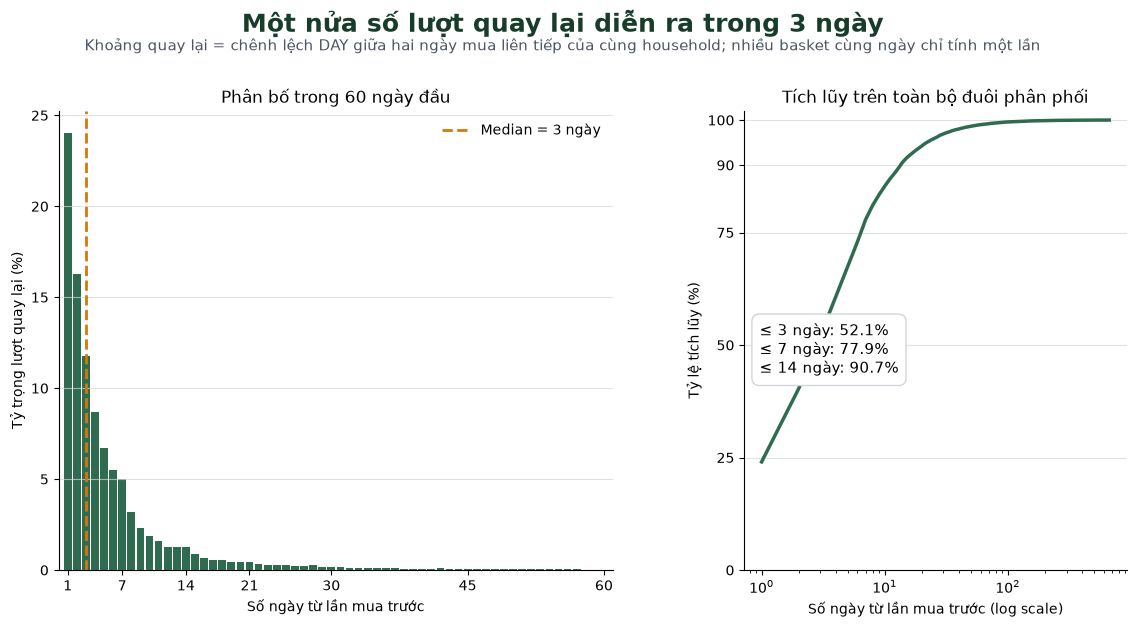

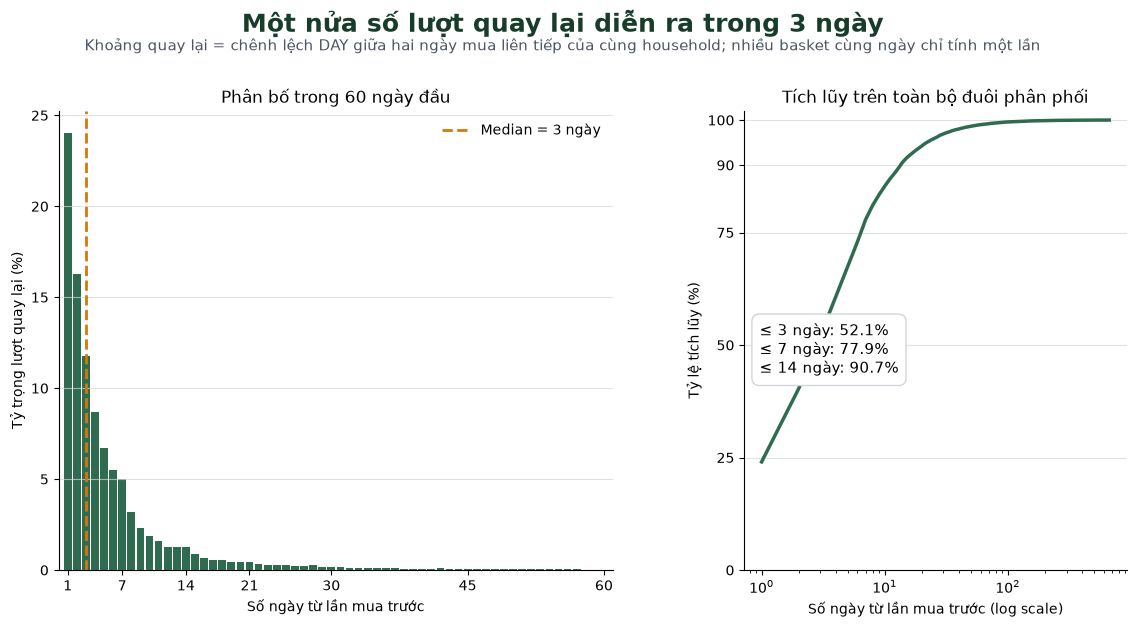

In [14]:
return_interval_figure = plot_return_interval_distribution(
    transaction_technical.return_intervals
)
return_interval_figure

#### Kết luận khoảng quay lại

- Có 223.033 khoảng quay lại hợp lệ từ 2.500 households.
- 24,0% lượt quay lại sau đúng 1 ngày; cumulative share đạt 52,1% trong 3 ngày, 77,9% trong 7 ngày và 90,7% trong 14 ngày.
- Median = 3 ngày, p90 = 14 ngày, p95 = 22 ngày và p99 = 61 ngày. Max = 666 ngày cho thấy đuôi phân phối dài.
- Đây là phân phối giữa các lần mua đã quan sát, chưa xử lý right censoring ở cuối DAY 711 và chưa phải xác suất churn.

### 9.6. Quan hệ kỹ thuật chọn lọc

Chỉ tính ba Pearson correlations có câu hỏi rõ ràng. Correlation được ghi kèm grain để tránh trộn product-line với household.

In [15]:
transaction_technical.relationships

grain,x,y,n_observations,pearson_correlation
str,str,str,u32,f64
"""product_line""","""QUANTITY""","""SALES_VALUE""",2595732,0.587993
"""product_line""","""discount_amount""","""SALES_VALUE""",2595732,0.250284
"""household""","""n_baskets""","""total_sales""",2500,0.70303


#### Kết luận cross-analysis

- Ở product-line grain, `QUANTITY` và `SALES_VALUE` có Pearson correlation 0,588. Quan hệ dương ở mức vừa nhưng bị ảnh hưởng bởi extreme quantity.
- Discount amount và `SALES_VALUE` có correlation 0,250. Con số này không chứng minh discount làm tăng sales vì chưa kiểm soát product, price, store hoặc campaign.
- Ở household grain, `n_baskets` và `total_sales` có correlation 0,703. Đây là full-history exposure relationship; muốn dùng cho propensity phải tính trong observation window.
- Không tạo correlation matrix cho ID hoặc mọi cặp numeric chỉ để kéo dài EDA.

## 10. Ranh giới với notebook business

Notebook này dừng sau khi mô tả cấu trúc và phân phối ở đúng grain. Notebook business riêng sẽ dùng các evidence tables để kể chuyện theo chủ đề:

- **Thời gian:** trend, seasonality, cohort và thay đổi cadence.
- **Sản phẩm:** preference sau khi join department, commodity, sub-commodity và brand.
- **Promotion:** sales và hành vi quay lại khi có retail discount, coupon hoặc campaign.
- **Khách hàng:** RFM và segment, nhưng mọi feature phải giới hạn theo observation window để tránh leakage.

Việc tách hai notebook giúp technical EDA trả lời “dữ liệu có đặc điểm gì”, còn business EDA trả lời “đặc điểm đó nói gì về hành vi”.

## 11. Load 7 bảng còn lại

Các bảng được scan lazy. Riêng `causal_data`, `display` và `mailer` được ép về `String` vì đây là mã phân loại; để Polars tự suy dtype sẽ đọc nhầm `display` thành số trước khi gặp mã chữ `A`.

## 12. Product — catalog composition và category hierarchy (4/5)

Thống kê ở đây trả lời catalog có gì, không suy diễn category nào được khách hàng mua nhiều. Nhu cầu thực tế chỉ đo được sau khi join với transaction.

In [ ]:
product_profile = profile_products(products, top_n=15)
display(product_profile.overview)
display(product_profile.cardinality)
display(product_profile.frequencies)
display(product_profile.hierarchy.group_by("level").head(10))

### Kết luận product

- 92.353 dòng tương ứng 92.353 `PRODUCT_ID` duy nhất; không có null trong 7 cột.
- Catalog gồm 6.476 manufacturer, 44 department, 308 commodity và 2.383 sub-commodity.
- `GROCERY` chiếm 42,25% và `DRUG GM` chiếm 34,14% số sản phẩm trong catalog; đây là catalog share, không phải sales share.
- `BRAND` có 2 mức: National 85,04% và Private 14,96%.
- `CURR_SIZE_OF_PRODUCT` có 4.345 chuỗi khác nhau, cần chuẩn hóa đơn vị trước khi dùng như size numeric.

## 13. Coupon redemption — event frequency và thời gian (4/5)

In [18]:
redemption_profile = profile_coupon_redemptions(
    coupon_redemptions, top_n=10
)
display(redemption_profile.overview)
display(redemption_profile.group_distributions)
display(redemption_profile.frequencies)
display(redemption_profile.daily_activity.describe())
display(redemption_profile.return_intervals.head(20))

n_redemptions,n_households,n_coupons,n_campaigns,min_day,max_day
u32,u32,u32,u32,i64,i64
2318,434,556,30,225,704


grain,n_groups,mean,std,p25,p50,p75,p90,p99,max
str,i64,f64,f64,f64,f64,f64,f64,f64,f64
"""household_key""",434,5.341014,6.052413,1.0,3.0,7.0,12.0,29.0,35.0
"""COUPON_UPC""",556,4.169065,6.787921,1.0,2.0,4.0,9.0,35.0,63.0
"""CAMPAIGN""",30,77.266667,167.242944,5.0,25.0,47.0,73.0,653.0,653.0


column,value,n_rows,share,rank
str,str,u32,f64,u32
"""household_key""","""367""",35,0.015099,1
"""household_key""","""67""",33,0.014236,2
"""household_key""","""256""",33,0.014236,3
"""household_key""","""1823""",30,0.012942,4
"""household_key""","""931""",29,0.012511,5
"""household_key""","""979""",28,0.012079,6
"""household_key""","""1591""",28,0.012079,7
"""household_key""","""2489""",28,0.012079,8
"""household_key""","""1726""",27,0.011648,9


statistic,DAY,n_redemptions,n_households,n_coupons
str,f64,f64,f64,f64
"""count""",328.0,328.0,328.0,328.0
"""null_count""",0.0,0.0,0.0,0.0
"""mean""",490.789634,7.067073,3.77439,6.161585
"""std""",129.869312,7.910533,3.438985,6.200137
"""min""",225.0,1.0,1.0,1.0
"""25%""",396.0,2.0,1.0,2.0
"""50%""",509.0,4.0,2.0,4.0
"""75%""",602.0,10.0,5.0,9.0
"""max""",704.0,47.0,23.0,29.0


interval_days,n_intervals,share
i64,u32,f64
1,9,0.011194
2,20,0.024876
3,17,0.021144
4,13,0.016169
5,16,0.0199
6,27,0.033582
7,34,0.042289
8,22,0.027363
9,18,0.022388


### Kết luận coupon_redempt

- Có 2.318 redemption events từ 434 households, 556 coupon và đủ 30 campaign; thời gian từ DAY 225 đến 704.
- Median một household redeem 3 lần; p90 là 12, p99 là 29 và max là 35. Phân phối lệch phải.
- Median một coupon được redeem 2 lần; p99 là 35 và max là 63.
- Bảng chỉ ghi nhận sự kiện đã redeem. Household không xuất hiện có thể chưa được gửi coupon, vì vậy không được tự động gán là “không quan tâm coupon”.

## 14. Campaign table — participation structure (3/5)

In [19]:
campaign_profile = profile_campaign_table(
    campaign_assignments, total_households=2_500
)
display(campaign_profile.overview)
display(campaign_profile.group_distributions)
campaign_profile.campaign_counts

n_rows,n_campaigns,n_households,n_unique_pairs,duplicate_pairs,total_households,coverage_ratio
i64,i64,i64,i64,i64,i64,f64
7208,30,1584,7208,0,2500,0.6336


grain,n_groups,mean,std,p25,p50,p75,p90,p99,max
str,i64,f64,f64,f64,f64,f64,f64,f64,f64
"""household_key""",1584,4.550505,2.993988,2.0,4.0,6.0,9.0,12.0,17.0
"""CAMPAIGN""",30,240.266667,304.411579,65.0,173.0,224.0,361.0,1133.0,1133.0


CAMPAIGN,DESCRIPTION,n_households
i64,str,u32
18,"""TypeA""",1133
13,"""TypeA""",1077
8,"""TypeA""",1076
30,"""TypeA""",361
26,"""TypeA""",332
22,"""TypeB""",276
20,"""TypeC""",244
14,"""TypeC""",224
11,"""TypeB""",214


### Kết luận campaign_table

- 7.208 cặp household–campaign đều unique, phủ 1.584/2.500 households (63,36%).
- Median household tham gia 4 campaign; p90 là 9 và max là 17.
- Quy mô campaign không đồng đều: median 173 households, p90 361, max 1.133.
- 916 households không có trong bảng assignment; cần giữ trạng thái “không được gán campaign” tách biệt với “được gán nhưng không redeem”.

## 15. Causal data — display/mailer theo product–store–week (3/5)

Bảng rất lớn nhưng các trường là ID hoặc categorical code. Vì vậy dùng frequency/group-by, không tính descriptive numeric cho mã.

In [20]:
causal_profile = profile_causal_data(causal, top_n=15)
display(causal_profile.overview)
display(causal_profile.code_frequencies)
display(causal_profile.group_distributions)
causal_profile.weekly_activity

n_rows,n_products,n_stores,n_weeks,n_display_codes,n_mailer_codes
u32,u32,u32,u32,u32,u32
36786524,68377,115,93,10,11


column,value,n_rows,share,rank
str,str,u32,f64,u32
"""display""","""0""",21038745,0.571914,1
"""display""","""9""",2699467,0.073382,2
"""display""","""5""",2575289,0.070006,3
"""display""","""7""",2362118,0.064212,4
"""display""","""3""",2073738,0.056372,5
"""display""","""6""",1816021,0.049366,6
"""display""","""2""",1812840,0.04928,7
"""display""","""1""",1102141,0.02996,8
"""display""","""A""",713180,0.019387,9


grain,n_groups,mean,std,p25,p50,p75,p90,p99,max
str,i64,f64,f64,f64,f64,f64,f64,f64,f64
"""PRODUCT_ID""",68377,537.995583,908.898798,18.0,142.0,607.0,1682.0,4262.0,7083.0
"""STORE_ID""",115,319882.817391,84002.019995,304917.0,342674.0,369071.0,386358.0,444806.0,469670.0
"""WEEK_NO""",93,395554.021505,54281.14854,362183.0,384701.0,412848.0,442452.0,574668.0,589575.0


WEEK_NO,n_rows,n_products,n_stores,n_display_codes,n_mailer_codes
i64,u32,u32,u32,u32,u32
9,398116,21543,107,10,7
10,346561,20442,107,10,7
11,498395,21774,107,10,7
12,374525,21251,107,10,7
13,422183,21266,107,10,8
14,375968,20657,107,10,7
15,384701,20526,107,10,6
16,542902,20242,107,10,6
17,389506,21253,107,10,5


### Kết luận causal_data

- 36.786.524 dòng, 68.377 products, 115 stores và 93 tuần; grain phân tích là product–store–week exposure.
- `display` có 10 code và `mailer` có 11 code. `display='0'` chiếm 57,19%; `mailer='0'` chiếm 31,35%.
- `mailer='A'` là code phổ biến nhất với 46,50%; không được hiểu chữ A như thứ hạng nếu chưa có data dictionary.
- Median một product xuất hiện ở 142 dòng exposure, p99 là 4.262 và max 7.083; coverage rất lệch giữa sản phẩm.
- Các code chỉ mô tả placement/mailer. Muốn đánh giá hiệu quả promotion phải join transaction theo product, store và week trong notebook business.

## 16. Household demographic — coverage và segment distribution (3/5)

In [ ]:
demographic_profile = profile_household_demographics(
    demographics, total_households=2_500, top_n=20
)
display(demographic_profile.overview)
display(demographic_profile.frequencies)
demographic_profile.segments

### Kết luận hh_demographic

- 801 household records đều unique và không có physical null, nhưng chỉ phủ 32,04% của 2.500 households giao dịch; 1.699 households phải giữ nhóm demographic unknown.
- Tất cả 7 attributes là categorical thấp cardinality; không tính mean/std trực tiếp trên các khoảng tuổi hoặc thu nhập dạng chuỗi.
- Nhóm tuổi lớn nhất là 45–54 (35,96%); hai income band phổ biến nhất là 50–74K (23,97%) và 35–49K (21,47%).
- Cross-tab chỉ mô tả 801 households có demographic, không đại diện chắc chắn cho toàn bộ population nếu missingness không ngẫu nhiên.

## 17. Coupon mapping — mapping multiplicity (2/5)

In [22]:
coupon_profile = profile_coupon_mappings(coupon_mappings)
display(coupon_profile.overview)
display(coupon_profile.group_distributions)
coupon_profile.campaign_counts

n_rows,n_coupons,n_products,n_campaigns,n_unique_mappings,n_duplicate_mappings
u32,u32,u32,u32,u32,u32
124548,1135,44133,30,119384,5164


grain,metric,n_groups,mean,std,p25,p50,p75,p90,p99,max
str,str,i64,f64,f64,f64,f64,f64,f64,f64,f64
"""COUPON_UPC""","""n_products""",1135,98.807048,763.351371,5.0,12.0,28.0,64.0,3842.0,14477.0
"""PRODUCT_ID""","""n_coupons""",44133,2.541092,1.186447,2.0,2.0,3.0,4.0,7.0,11.0
"""CAMPAIGN""","""n_coupons""",30,46.566667,69.301781,12.0,17.5,28.0,181.0,209.0,209.0


CAMPAIGN,n_coupons,n_products,n_mappings
i64,u32,u32,u32
1,11,383,383
2,16,301,301
3,34,506,740
4,12,200,200
5,11,443,443
6,1,18,18
7,8,259,259
8,209,17178,19206
9,18,825,825


### Kết luận coupon

- 124.548 dòng liên kết 1.135 coupons với 44.133 products trong 30 campaigns; có 119.384 bộ ba coupon–product–campaign unique và 5.164 dòng trùng bộ ba cần kiểm tra trước khi join.
- Một coupon áp dụng cho median 12 products distinct; p90 là 64, p99 là 3.842 và max 14.477. Một product thuộc median 2 coupons distinct; p99 là 7 và max 11.
- Mapping có thể thay đổi theo campaign; khi join cần dùng cả `COUPON_UPC` và `CAMPAIGN`, không chỉ coupon ID.

## 18. Campaign description — timing summary (1/5)

In [23]:
campaign_desc_profile = profile_campaign_descriptions(
    campaign_descriptions
)
display(campaign_desc_profile.overview)
display(campaign_desc_profile.type_counts)
display(campaign_desc_profile.duration_summary)
campaign_desc_profile.campaigns

n_campaigns,min_start_day,max_end_day,n_overlapping_pairs
i64,i64,i64,i64
30,224,719,74


DESCRIPTION,n_campaigns
str,u32
"""TypeB""",19
"""TypeC""",6
"""TypeA""",5


min,mean,median,max
i64,f64,f64,i64
33,47.6,38.5,162


DESCRIPTION,CAMPAIGN,START_DAY,END_DAY,duration_days
str,i64,i64,i64,i64
"""TypeB""",1,346,383,38
"""TypeB""",2,351,383,33
"""TypeC""",3,356,412,57
"""TypeB""",4,372,404,33
"""TypeB""",5,377,411,35
"""TypeC""",6,393,425,33
"""TypeB""",7,398,432,35
"""TypeA""",8,412,460,49
"""TypeB""",9,435,467,33


### Kết luận campaign_desc

- Có đúng 30 campaigns: 19 TypeB, 6 TypeC và 5 TypeA.
- Campaign chạy từ DAY 224 đến 719; duration min 33, median 38,5, mean 47,6 và max 162 ngày.
- Có 74 cặp campaign chồng lấn thời gian. Vì chỉ có 30 dòng, bảng đầy đủ hữu ích hơn việc tạo nhiều histogram.
- DAY 719 vượt max DAY 711 của transaction, nên các campaign cuối có thể bị right-censoring trong dữ liệu mua hàng.

## 19. Tổng kết 

Notebook này đã hoàn tất câu hỏi “mỗi bảng có đặc điểm kỹ thuật gì”. Phần tiếp theo mới join bảng để kể chuyện business theo thời gian, sản phẩm, promotion và khách hàng.